# 🛡️ FraudLake — Jour 2 : Modèle d'exécution Spark, Jointure multi-sources & Couche Silver

| Bronze (J1) | Silver (J2) | Gold (J3) | Statistiques, ML & Dashboard (J4) |
|:---:|:---:|:---:|:---:|
| ingestion brute + lignage ✅ | **▶ nettoyage, pseudonymisation, features** | KPI & agrégats SQL | tests, segmentation, scoring |

### 🎯 Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur la Spark UI (`:4040`).
2. **Profiler la qualité** des tables Bronze (valeurs manquantes, vides masqués, doublons, incohérences de domaine).
3. **Pseudonymiser** les données personnelles (RGPD) et construire des **features anti-fraude** : temporelles, géographiques et de **vélocité** par carte (fonctions de fenêtrage).
4. **Joindre** les transactions au calendrier des jours fériés (`BroadcastHashJoin`) en **prévenant l'explosion N-à-M**.
5. Écrire la table **`/lakehouse/silver/transactions_enriched`** et démontrer les garanties **ACID** de Delta Lake
   (`_delta_log`, *Schema Enforcement*, `MERGE INTO`, *Time Travel*, `RESTORE`).

In [1]:
import time

import numpy as np
import pandas as pd
from delta.tables import DeltaTable
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # pandas 3 / PySpark : avertissement sans impact
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Session Spark active — Spark UI : http://localhost:4040")

# --- Charte graphique commune aux notebooks FraudLake --------------------------
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)   # avertissements pandas 3 / PySpark sans impact

LEGIT, FRAUD, NEUTRAL = "#2a78d6", "#eb6834", "#9a9893"   # bleu = légitime, orange = fraude
CLASS_COLORS = {"Légitime": LEGIT, "Fraude": FRAUD}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "grid.color": "#e6e5e1",
    "legend.frameon": False,
})

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-17633e9d-9ce7-48c5-bf93-fbcc012ea130;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central


	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central


	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 474ms :: artifacts dl 24ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jacks

26/11/21 07:49:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Session Spark active — Spark UI : http://localhost:4040


## 1. Chargement des tables Bronze & diagnostic qualité

### Exercice 1.1 — Profil des valeurs manquantes (vraies `NULL` **et** vides masqués)
Un `NULL` n'est pas la seule forme d'absence : chaînes vides, `"null"`, `"n/a"`, `"unknown"`… sont des **vides masqués**
que `isNull()` ne détecte pas. Le profil ci-dessous compte les deux, colonne par colonne.

In [2]:
BRONZE_TABLES: dict[str, str] = {
    "main": "/lakehouse/bronze/transactions",     # Dataset 1 : table de faits (transactions CB)
    "secondary": "/lakehouse/bronze/us_holidays",  # Dataset 2 : calendrier des jours fériés US
}
bronze_dfs = {alias: spark.read.format("delta").load(path) for alias, path in BRONZE_TABLES.items()}
for alias, df in bronze_dfs.items():
    print(f"[{alias:<9}] {BRONZE_TABLES[alias]:<32} -> {df.count():>10,} lignes | {len(df.columns)} colonnes")

df_bronze = bronze_dfs["main"]
df_hol_bz = bronze_dfs["secondary"]
SENTINELS = ["", "null", "none", "nan", "n/a", "na", "?", "unknown"]


def missing_profile(df, table: str):
    cols = [(c, t) for c, t in df.dtypes if not c.startswith("_")]
    exprs = []
    for c, t in cols:
        exprs.append(F.sum(F.col(c).isNull().cast("int")).alias(f"{c}__null"))
        sentinel = F.lower(F.trim(F.col(c))).isin(SENTINELS) if t == "string" else F.lit(False)
        exprs.append(F.sum(sentinel.cast("int")).alias(f"{c}__masked"))
    row = df.select(F.count("*").alias("__n"), *exprs).first().asDict()
    n = row.pop("__n")
    return [(table, c, t, row[f"{c}__null"], row[f"{c}__masked"],
             round(100 * (row[f"{c}__null"] + row[f"{c}__masked"]) / n, 4)) for c, t in cols]


null_report = spark.createDataFrame(
    missing_profile(df_bronze, "transactions") + missing_profile(df_hol_bz, "us_holidays"),
    "table string, colonne string, type string, nb_null long, nb_vides_masques long, pct_manquant double",
).orderBy(F.desc("pct_manquant"), "table", "colonne")
null_report.show(40, truncate=False)

[main     ] /lakehouse/bronze/transactions   ->  1,852,394 lignes | 27 colonnes


[secondary] /lakehouse/bronze/us_holidays    ->        342 lignes | 10 colonnes


+------------+---------------------+------+-------+----------------+------------+
|table       |colonne              |type  |nb_null|nb_vides_masques|pct_manquant|
+------------+---------------------+------+-------+----------------+------------+
|transactions|amt                  |double|0      |0               |0.0         |
|transactions|category             |string|0      |0               |0.0         |
|transactions|cc_num               |string|0      |0               |0.0         |
|transactions|city                 |string|0      |0               |0.0         |
|transactions|city_pop             |bigint|0      |0               |0.0         |
|transactions|dob                  |string|0      |0               |0.0         |
|transactions|first                |string|0      |0               |0.0         |
|transactions|gender               |string|0      |0               |0.0         |
|transactions|is_fraud             |int   |0      |0               |0.0         |
|transactions|jo

In [3]:
# Doublons, déséquilibre de classes et cohérence des horodatages
n_total = df_bronze.count()
n_distinct_tx = df_bronze.select("trans_num").distinct().count()
print(f"Transactions : {n_total:,} | identifiants `trans_num` distincts : {n_distinct_tx:,} | doublons : {n_total - n_distinct_tx:,}")
print(f"Doublons exacts (toutes colonnes métier) : {n_total - df_bronze.drop('_source_file', '_ingested_at').dropDuplicates().count():,}")

print("\n=== Déséquilibre de la cible `is_fraud` ===")
df_bronze.groupBy("is_fraud").agg(
    F.count("*").alias("transactions"), F.round(100 * F.count("*") / F.lit(n_total), 3).alias("pct")
).orderBy("is_fraud").show()

print("=== Incohérence détectée : `unix_time` vs `trans_date_trans_time` ===")
df_bronze.select(
    F.min("trans_date_trans_time").alias("date_min_texte"),
    F.from_unixtime(F.min("unix_time")).alias("date_min_unix_time"),
    F.round(F.avg((F.unix_timestamp(F.to_timestamp("trans_date_trans_time")) - F.col("unix_time")) / 86400 / 365.25), 2)
     .alias("decalage_moyen_annees"),
).show(truncate=False)

print("=== Calendrier : dates présentes plusieurs fois (risque N-à-M) ===")
df_hol_bz.groupBy("date").agg(F.count("*").alias("nb"), F.collect_list("holiday").alias("holidays")) \
    .filter("nb > 1").orderBy("date").show(truncate=False)

Transactions : 1,852,394 | identifiants `trans_num` distincts : 1,852,394 | doublons : 0


Doublons exacts (toutes colonnes métier) : 0

=== Déséquilibre de la cible `is_fraud` ===


+--------+------------+------+
|is_fraud|transactions|   pct|
+--------+------------+------+
|       0|     1842743|99.479|
|       1|        9651| 0.521|
+--------+------------+------+

=== Incohérence détectée : `unix_time` vs `trans_date_trans_time` ===


+-------------------+-------------------+---------------------+
|date_min_texte     |date_min_unix_time |decalage_moyen_annees|
+-------------------+-------------------+---------------------+
|2019-01-01 00:00:18|2012-01-01 00:00:18|7.0                  |
+-------------------+-------------------+---------------------+

=== Calendrier : dates présentes plusieurs fois (risque N-à-M) ===


+----------+---+--------------------------------+
|date      |nb |holidays                        |
+----------+---+--------------------------------+
|2004-04-11|2  |[Western Easter, Eastern Easter]|
|2007-04-08|2  |[Western Easter, Eastern Easter]|
|2010-04-04|2  |[Western Easter, Eastern Easter]|
|2011-04-24|2  |[Western Easter, Eastern Easter]|
|2014-04-20|2  |[Western Easter, Eastern Easter]|
|2017-04-16|2  |[Western Easter, Eastern Easter]|
+----------+---+--------------------------------+



### Exercice 1.2 — *Lazy Evaluation* : Narrow vs Wide
Les transformations (`filter`, `withColumn`, `groupBy`…) ne font que **construire un plan** ; seule une **action**
(`count`, `write`, `show`…) déclenche le calcul. Une transformation *wide* (`groupBy`, `join` non broadcast, `Window`) impose
un **Shuffle** : redistribution réseau des lignes par clé, matérialisée par un opérateur `Exchange` dans le plan physique
et par une **frontière de *stage*** dans la Spark UI.

In [4]:
t0 = time.perf_counter()
narrow = df_bronze.filter(F.col("amt") > 0).withColumn("amt_eur", F.round(F.col("amt") * 0.92, 2))   # Narrow
wide = narrow.groupBy("category").agg(F.count("*").alias("n"), F.sum("is_fraud").alias("fraudes"))  # Wide
t_plan = time.perf_counter() - t0

t0 = time.perf_counter()
n_categories = wide.count()                                                                             # Action
t_exec = time.perf_counter() - t0

narrow_plan = narrow._jdf.queryExecution().executedPlan().toString()
wide_plan = wide._jdf.queryExecution().executedPlan().toString()
print(f"Déclaration des transformations : {t_plan * 1000:7.1f} ms  (aucun job Spark lancé)")
print(f"Exécution de l'action count()    : {t_exec * 1000:7.1f} ms  ({n_categories} catégories)")
print(f"Shuffle (Exchange) dans le plan narrow ? {'Exchange' in narrow_plan}")
print(f"Shuffle (Exchange) dans le plan wide   ? {'Exchange' in wide_plan}")
wide.explain("simple")

Déclaration des transformations :    80.2 ms  (aucun job Spark lancé)
Exécution de l'action count()    :  3499.6 ms  (14 catégories)
Shuffle (Exchange) dans le plan narrow ? False
Shuffle (Exchange) dans le plan wide   ? True
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[category#4], functions=[count(1), sum(is_fraud#22)])
   +- Exchange hashpartitioning(category#4, 200), ENSURE_REQUIREMENTS, [plan_id=985]
      +- HashAggregate(keys=[category#4], functions=[partial_count(1), partial_sum(is_fraud#22)])
         +- Project [category#4, is_fraud#22]
            +- Filter (isnotnull(amt#5) AND (amt#5 > 0.0))
               +- FileScan parquet [category#4,amt#5,is_fraud#22] Batched: true, DataFilters: [isnotnull(amt#5), (amt#5 > 0.0)], Format: Parquet, Location: PreparedDeltaFileIndex(1 paths)[hdfs://namenode:9000/lakehouse/bronze/transactions], PartitionFilters: [], PushedFilters: [IsNotNull(amt), GreaterThan(amt,0.0)], ReadSchema: struct<category:string,a

#### 📌 Bilan du diagnostic & décisions de traitement

| Constat | Mesure | Décision |
|---|---|---|
| Valeurs manquantes | **0 `NULL` et 0 vide masqué** sur les 23 colonnes | Pas d'imputation nécessaire ; la règle `clean_str` reste appliquée par sécurité (pipeline réutilisable sur de futurs lots). |
| Doublons | 0 doublon sur `trans_num` | `dropDuplicates(["trans_num"])` conservé (idempotence en cas de ré-ingestion). |
| **Déséquilibre de classes** | **0,521 %** de fraudes (9 651 / 1 852 394) | Indicateurs robustes (taux, PR-AUC) plutôt que l'*accuracy* ; sous-échantillonnage au Jour 4. |
| **Incohérence temporelle** | `unix_time` décalé de **7 ans** (2012 → 2013 au lieu de 2019 → 2020) | Colonne **écartée** ; l'epoch est recalculé depuis `trans_date_trans_time`. |
| Préfixe artificiel | 100 % des marchands commencent par `fraud_` (artefact du simulateur) | Préfixe supprimé (sinon confusion « fraud » ≠ fraude). |
| Données personnelles | nom, prénom, rue, n° de carte, date de naissance | **Pseudonymisation** : `cc_num` → `card_id` (SHA-256 salé), `dob` → `age`, suppression des identifiants directs. |
| Calendrier | dates doublonnées (Pâques orthodoxe = Pâques catholique certaines années) | **Pré-agrégation par date** avant jointure (clé unique côté dimension). |

---
## 2. Nettoyage, pseudonymisation & validation de domaine

In [5]:
def clean_str(col_name: str):
    """Harmonisation typographique : trim + espaces multiples + vides masqués -> NULL."""
    norm = F.regexp_replace(F.trim(F.col(col_name)), r"\s+", " ")
    return F.when(norm.isNull() | F.lower(norm).isin(SENTINELS), F.lit(None)).otherwise(norm)


PSEUDO_SALT = "fraudlake-2026"   # ⚠️ en production : secret stocké dans un coffre (Vault / KMS), jamais dans le code

tx_typed = (
    df_bronze
    .dropDuplicates(["trans_num"])
    .withColumn("trans_ts", F.to_timestamp("trans_date_trans_time", "yyyy-MM-dd HH:mm:ss"))
    .withColumn("dob", F.to_date("dob", "yyyy-MM-dd"))
    .withColumn("merchant", F.regexp_replace(clean_str("merchant"), r"^fraud_", ""))
    .withColumn("category", F.lower(clean_str("category")))
    .withColumn("state", F.upper(clean_str("state")))
    .withColumn("gender", F.upper(clean_str("gender")))
    .withColumn("card_id", F.substring(F.sha2(F.concat_ws("|", F.lit(PSEUDO_SALT), F.col("cc_num")), 256), 1, 16))
    .withColumn("dataset_split", F.when(F.col("_source_file").contains("train"), "train").otherwise("test"))
    .withColumn("age", F.floor(F.months_between(F.col("trans_ts"), F.col("dob")) / 12).cast("int"))
)

# Audit chiffré des règles de domaine (un seul passage sur les données)
DOMAIN_RULES = {
    "Horodatage illisible (trans_ts NULL)": F.col("trans_ts").isNull(),
    "Montant <= 0": F.col("amt") <= 0,
    "Coordonnées porteur hors domaine": ~F.col("lat").between(-90, 90) | ~F.col("long").between(-180, 180),
    "Coordonnées commerçant hors domaine": ~F.col("merch_lat").between(-90, 90) | ~F.col("merch_long").between(-180, 180),
    "Cible hors {0, 1}": ~F.col("is_fraud").isin(0, 1),
    "Âge incohérent (< 13 ou > 100 ans)": ~F.col("age").between(13, 100),
    "Population de ville <= 0": F.col("city_pop") <= 0,
}
audit_row = tx_typed.select(
    *[F.sum(F.coalesce(cond, F.lit(True)).cast("int")).alias(name) for name, cond in DOMAIN_RULES.items()]
).first().asDict()
display(pd.DataFrame({"règle de domaine": audit_row.keys(), "violations": audit_row.values()}).style.hide(axis="index"))

violates_any_rule = F.greatest(*[F.coalesce(cond, F.lit(True)).cast("int") for cond in DOMAIN_RULES.values()])
tx_clean = tx_typed.filter(violates_any_rule == 0).drop(
    "cc_num", "first", "last", "street", "zip", "city", "job", "dob", "unix_time", "row_id", "trans_date_trans_time"
)
print("Colonnes conservées après minimisation RGPD :", tx_clean.columns)

règle de domaine,violations
Horodatage illisible (trans_ts NULL),0
Montant <= 0,0
Coordonnées porteur hors domaine,0
Coordonnées commerçant hors domaine,0
"Cible hors {0, 1}",0
Âge incohérent (< 13 ou > 100 ans),0
Population de ville <= 0,0


Colonnes conservées après minimisation RGPD : ['merchant', 'category', 'amt', 'gender', 'state', 'lat', 'long', 'city_pop', 'trans_num', 'merch_lat', 'merch_long', 'is_fraud', '_ingested_at', '_source_dataset', '_source_file', '_batch_id', 'trans_ts', 'card_id', 'dataset_split', 'age']


## 3. *Feature engineering* anti-fraude

| Feature | Calcul | Intuition métier |
|---|---|---|
| `hour`, `weekday_num`, `is_weekend`, `is_night` | extraits de `trans_ts` (nuit = 22 h → 4 h) | les fraudeurs agissent souvent la nuit, quand le porteur dort |
| `is_online` | catégorie `*_net` | la fraude « carte non présente » domine en e-commerce |
| `distance_km` | **Haversine** entre domicile du porteur et commerçant | achat inhabituellement lointain |
| `amt_log` | $\log(1 + \text{amt})$ | réduit l'asymétrie extrême des montants |
| `txn_count_24h`, `amt_sum_24h` | `Window` par carte, `rangeBetween(-86 400 s, 0)` | **vélocité** : rafale d'achats en peu de temps |
| `secs_since_prev_txn` | `LAG(epoch)` par carte | enchaînement anormalement rapide |
| `amt_ratio_to_card_mean` | montant / moyenne **historique** de la carte (`rowsBetween(unboundedPreceding, -1)`) | montant atypique *pour ce client* |

> ⚠️ **Pas de fuite d'information (*data leakage*)** : toutes les fenêtres ne regardent que le **passé** de chaque carte
> (jamais les transactions futures), condition indispensable pour réutiliser ces features dans le modèle du Jour 4.
> Les trois fenêtres partagent la même partition (`card_id`) et le même tri : Spark les calcule avec **un seul Shuffle**.

In [6]:
EARTH_RADIUS_KM = 6371.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = [F.radians(F.col(c)) for c in (lat1, lon1, lat2, lon2)]
    a = F.sin((lat2 - lat1) / 2) ** 2 + F.cos(lat1) * F.cos(lat2) * F.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * F.asin(F.sqrt(a))


w_card = Window.partitionBy("card_id").orderBy("event_epoch")
w_24h = w_card.rangeBetween(-86_400, 0)
w_hist = w_card.rowsBetween(Window.unboundedPreceding, -1)

tx_feat = (
    tx_clean
    .withColumn("event_epoch", F.unix_timestamp("trans_ts"))
    .withColumn("trans_date", F.to_date("trans_ts"))
    .withColumn("trans_month", F.date_format("trans_ts", "yyyy-MM"))
    .withColumn("hour", F.hour("trans_ts"))
    .withColumn("weekday_num", ((F.dayofweek("trans_ts") + 5) % 7) + 1)          # ISO : lundi = 1 … dimanche = 7
    .withColumn("is_weekend", (F.col("weekday_num") >= 6).cast("int"))
    .withColumn("is_night", ((F.col("hour") >= 22) | (F.col("hour") < 4)).cast("int"))
    .withColumn("is_online", F.col("category").endswith("_net").cast("int"))
    .withColumn("distance_km", F.round(haversine_km("lat", "long", "merch_lat", "merch_long"), 2))
    .withColumn("amt_log", F.round(F.log1p("amt"), 5))
    .withColumn("city_pop_log", F.round(F.log1p("city_pop"), 5))
    .withColumn("txn_count_24h", F.count("*").over(w_24h))
    .withColumn("amt_sum_24h", F.round(F.sum("amt").over(w_24h), 2))
    .withColumn("secs_since_prev_txn", F.col("event_epoch") - F.lag("event_epoch").over(w_card))
    .withColumn("card_amt_mean_hist", F.round(F.avg("amt").over(w_hist), 2))
    .withColumn("amt_ratio_to_card_mean", F.round(F.col("amt") / F.col("card_amt_mean_hist"), 3))
    .fillna({"secs_since_prev_txn": 30 * 86_400, "amt_ratio_to_card_mean": 1.0})   # 1ʳᵉ transaction de la carte
    .drop("lat", "long", "merch_lat", "merch_long")
)
tx_feat.select("card_id", "trans_ts", "amt", "txn_count_24h", "amt_sum_24h", "secs_since_prev_txn",
               "amt_ratio_to_card_mean", "distance_km", "is_night", "is_fraud").show(6, truncate=False)

+----------------+-------------------+-----+-------------+-----------+-------------------+----------------------+-----------+--------+--------+
|card_id         |trans_ts           |amt  |txn_count_24h|amt_sum_24h|secs_since_prev_txn|amt_ratio_to_card_mean|distance_km|is_night|is_fraud|
+----------------+-------------------+-----+-------------+-----------+-------------------+----------------------+-----------+--------+--------+
|02aae92a1f387b30|2019-01-01 03:49:49|30.69|1            |30.69      |2592000            |1.0                   |86.49      |1       |0       |
|02aae92a1f387b30|2019-01-01 05:00:03|62.13|2            |92.82      |4214               |2.024                 |65.88      |0       |0       |
|02aae92a1f387b30|2019-01-01 09:08:53|81.59|3            |174.41     |14930              |1.758                 |54.02      |0       |0       |
|02aae92a1f387b30|2019-01-01 12:28:41|19.12|4            |193.53     |11988              |0.329                 |54.12      |0       |0 

## 4. Jointure avec le calendrier des jours fériés (`BroadcastHashJoin`) sans explosion N-à-M

**Problème.** Une fraude « opportuniste » profite des pics d'achats festifs (Thanksgiving, Noël…). Pour le mesurer, on rattache
chaque transaction au **jour férié le plus proche à ± 3 jours**. Mais une même date peut se trouver dans la fenêtre de
**plusieurs** jours fériés (24 décembre = veille de Noël *et* J-1 de Noël *et* J-7 du réveillon…) : une jointure naïve
dupliquerait les transactions.

**Solution.** Construire une **dimension calendrier à clé unique** (`cal_date`) en pré-agrégeant : distance minimale au jour
férié et nom du jour férié le plus proche (`min_by`). Cette dimension (quelques centaines de lignes) est **diffusée**
(`F.broadcast`) à tous les exécuteurs : la grande table n'est jamais *shufflée*.

In [7]:
hol_clean = (
    df_hol_bz
    .select(F.to_date(F.col("date").cast("string")).alias("holiday_date"),
            F.regexp_replace(clean_str("holiday"), "’", "'").alias("holiday_name"))
    .dropna()
    .dropDuplicates(["holiday_date", "holiday_name"])
)
offsets = spark.range(-3, 4).select(F.col("id").cast("int").alias("offset"))
hol_window = hol_clean.crossJoin(offsets).withColumn("cal_date", F.date_add("holiday_date", F.col("offset")))

calendar_dim = (
    hol_window.groupBy("cal_date")
    .agg(
        F.min(F.abs("offset")).alias("days_to_holiday"),
        F.min_by("holiday_name", F.abs("offset")).alias("nearest_holiday"),
        F.min_by("offset", F.abs("offset")).alias("holiday_offset"),
    )
)
assert calendar_dim.count() == calendar_dim.select("cal_date").distinct().count(), "Clé non unique côté dimension !"

# 🧪 Démonstration de l'explosion N-à-M évitée
dates_only = tx_clean.select(F.to_date("trans_ts").alias("trans_date"))
count_before_join = dates_only.count()
naive_count = dates_only.join(F.broadcast(hol_window), F.col("trans_date") == F.col("cal_date"), "left").count()
safe_count = dates_only.join(F.broadcast(calendar_dim), F.col("trans_date") == F.col("cal_date"), "left").count()
print(f"Transactions avant jointure          : {count_before_join:>12,}")
print(f"Jointure naïve (fenêtres explosées)  : {naive_count:>12,}  (+{naive_count - count_before_join:,} lignes fantômes ❌)")
print(f"Jointure sur dimension à clé unique  : {safe_count:>12,}  ✅")

cal_years = hol_clean.agg(F.min(F.year("holiday_date")), F.max(F.year("holiday_date"))).first()
print(f"Couverture du calendrier : {cal_years[0]} → {cal_years[1]} (transactions : 2019 → 2020) ✅")

Transactions avant jointure          :    1,852,394
Jointure naïve (fenêtres explosées)  :    2,055,483  (+203,089 lignes fantômes ❌)
Jointure sur dimension à clé unique  :    1,852,394  ✅


Couverture du calendrier : 2004 → 2021 (transactions : 2019 → 2020) ✅


In [8]:
SILVER_MAIN_PATH = "/lakehouse/silver/transactions_enriched"

df_joined = (
    tx_feat
    .join(F.broadcast(calendar_dim), F.col("trans_date") == F.col("cal_date"), "left")
    .drop("cal_date")
    .withColumn("days_to_holiday", F.coalesce(F.col("days_to_holiday"), F.lit(4)))    # 4 = « plus de 3 jours »
    .withColumn("is_holiday", (F.col("days_to_holiday") == 0).cast("int"))
    .withColumn("is_holiday_window", (F.col("days_to_holiday") <= 3).cast("int"))
)

# Valeurs extrêmes : IQR (robuste) vs Z-score (sensible à l'asymétrie) sur le montant
q1, med, q3 = df_joined.approxQuantile("amt", [0.25, 0.5, 0.75], 0.0005)
mean_amt, std_amt = df_joined.agg(F.mean("amt"), F.stddev("amt")).first()
iqr = q3 - q1
upper_iqr = q3 + 1.5 * iqr
print(f"Montant — Q1={q1:.2f} | médiane={med:.2f} | Q3={q3:.2f} | IQR={iqr:.2f} | seuil IQR={upper_iqr:.2f} $")
print(f"Montant — moyenne={mean_amt:.2f} | écart-type={std_amt:.2f} | seuil Z>3 = {mean_amt + 3 * std_amt:.2f} $")

df_silver = (
    df_joined
    .withColumn("is_amt_outlier_iqr", (F.col("amt") > upper_iqr).cast("int"))
    .withColumn("is_amt_outlier_z", (F.abs((F.col("amt") - mean_amt) / std_amt) > 3).cast("int"))
    .withColumn("amt_robust_scaled", F.round((F.col("amt") - med) / iqr, 4))
    .withColumn("label_source", F.lit("initial"))
    .select(
        "trans_num", "card_id", "trans_ts", "trans_date", "trans_month", "event_epoch", "dataset_split",
        "merchant", "category", "amt", "amt_log", "amt_robust_scaled", "is_amt_outlier_iqr", "is_amt_outlier_z",
        "gender", "age", "state", "city_pop", "city_pop_log",
        "hour", "weekday_num", "is_weekend", "is_night", "is_online", "distance_km",
        "txn_count_24h", "amt_sum_24h", "secs_since_prev_txn", "card_amt_mean_hist", "amt_ratio_to_card_mean",
        "days_to_holiday", "holiday_offset", "nearest_holiday", "is_holiday", "is_holiday_window",
        "is_fraud", "label_source",
    )
)
df_silver.explain("simple")

(
    df_silver.write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .partitionBy("trans_month")
    .save(SILVER_MAIN_PATH)
)

silver = spark.read.format("delta").load(SILVER_MAIN_PATH)
silver_count = silver.count()
assert silver_count <= count_before_join, (
    f"Alerte explosion N-M : {silver_count:,} lignes après jointure > {count_before_join:,} lignes avant jointure !"
)
match = silver.agg(F.avg("is_holiday_window"), F.avg("is_holiday")).first()
print(f"Table Silver écrite dans {SILVER_MAIN_PATH} : {silver_count:,} lignes, {len(silver.columns)} colonnes, "
      f"partitionnée par mois")
print(f"Transactions rattachées à une fenêtre de jour férié (±3 j) : {100 * match[0]:.1f} % | jour férié exact : {100 * match[1]:.1f} %")

print("\n=== Confrontation IQR vs Z-score : les fraudes se cachent-elles dans les valeurs extrêmes ? ===")
silver.groupBy("is_amt_outlier_iqr", "is_amt_outlier_z").agg(
    F.count("*").alias("transactions"), F.round(100 * F.avg("is_fraud"), 2).alias("taux_fraude_pct")
).orderBy("is_amt_outlier_iqr", "is_amt_outlier_z").show()

Montant — Q1=9.64 | médiane=47.43 | Q3=83.06 | IQR=73.42 | seuil IQR=193.19 $
Montant — moyenne=70.06 | écart-type=159.25 | seuil Z>3 = 547.83 $


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [trans_num#18, card_id#3335, trans_ts#3329, trans_date#3626, trans_month#3627, event_epoch#3625L, dataset_split#3336, merchant#3331, category#3332, amt#5675, amt_log#3634, round(((amt#5675 - 47.43) / 73.42), 4) AS amt_robust_scaled#5662, cast((amt#5675 > 193.19) as int) AS is_amt_outlier_iqr#5660, cast((abs(((amt#5675 - 70.06356747538577) / 159.25397477398351)) > 3.0) as int) AS is_amt_outlier_z#5661, gender#3334, age#3337, state#3333, city_pop#5695L, city_pop_log#3635, hour#3628, weekday_num#3629, is_weekend#3630, is_night#3631, is_online#3632, distance_km#3633, ... 12 more fields]
   +- Project [merchant#3331, category#3332, amt#5675, gender#3334, state#3333, city_pop#5695L, trans_num#18, is_fraud#5707, trans_ts#3329, card_id#3335, dataset_split#3336, age#3337, event_epoch#3625L, trans_date#3626, trans_month#3627, hour#3628, weekday_num#3629, is_weekend#3630, is_night#3631, is_online#3632, distance_km#3633, amt_log#36

Table Silver écrite dans /lakehouse/silver/transactions_enriched : 1,852,394 lignes, 37 colonnes, partitionnée par mois
Transactions rattachées à une fenêtre de jour férié (±3 j) : 27.2 % | jour férié exact : 5.4 %

=== Confrontation IQR vs Z-score : les fraudes se cachent-elles dans les valeurs extrêmes ? ===


+------------------+----------------+------------+---------------+
|is_amt_outlier_iqr|is_amt_outlier_z|transactions|taux_fraude_pct|
+------------------+----------------+------------+---------------+
|                 0|               0|     1757214|           0.13|
|                 1|               0|       77334|           3.48|
|                 1|               1|       17846|          25.92|
+------------------+----------------+------------+---------------+



> **Lecture.** Le seuil IQR (**193 $**) signale **5,1 %** des transactions, contre **1,0 %** pour le Z-score (seuil 548 $) :
> l'écart-type, gonflé par une queue de distribution très longue (jusqu'à 28 949 $), place la barre si haut que le Z-score
> ignore toute la zone 193 – 548 $. Or ces 77 000 transactions « outliers IQR seulement » affichent déjà **3,5 % de fraude**
> (≈ 7× le taux de base de 0,52 %), et les outliers communs aux deux méthodes montent à **≈ 26 %**. Les flags sont conservés
> comme features — on ne supprime **pas** ces lignes : en détection de fraude, les valeurs extrêmes sont le signal recherché.

---
## 5. 🔍 Analyse exploratoire visuelle de la couche Silver
Les agrégations sont calculées par Spark ; seuls les résultats compacts sont rapatriés vers pandas pour l'affichage.

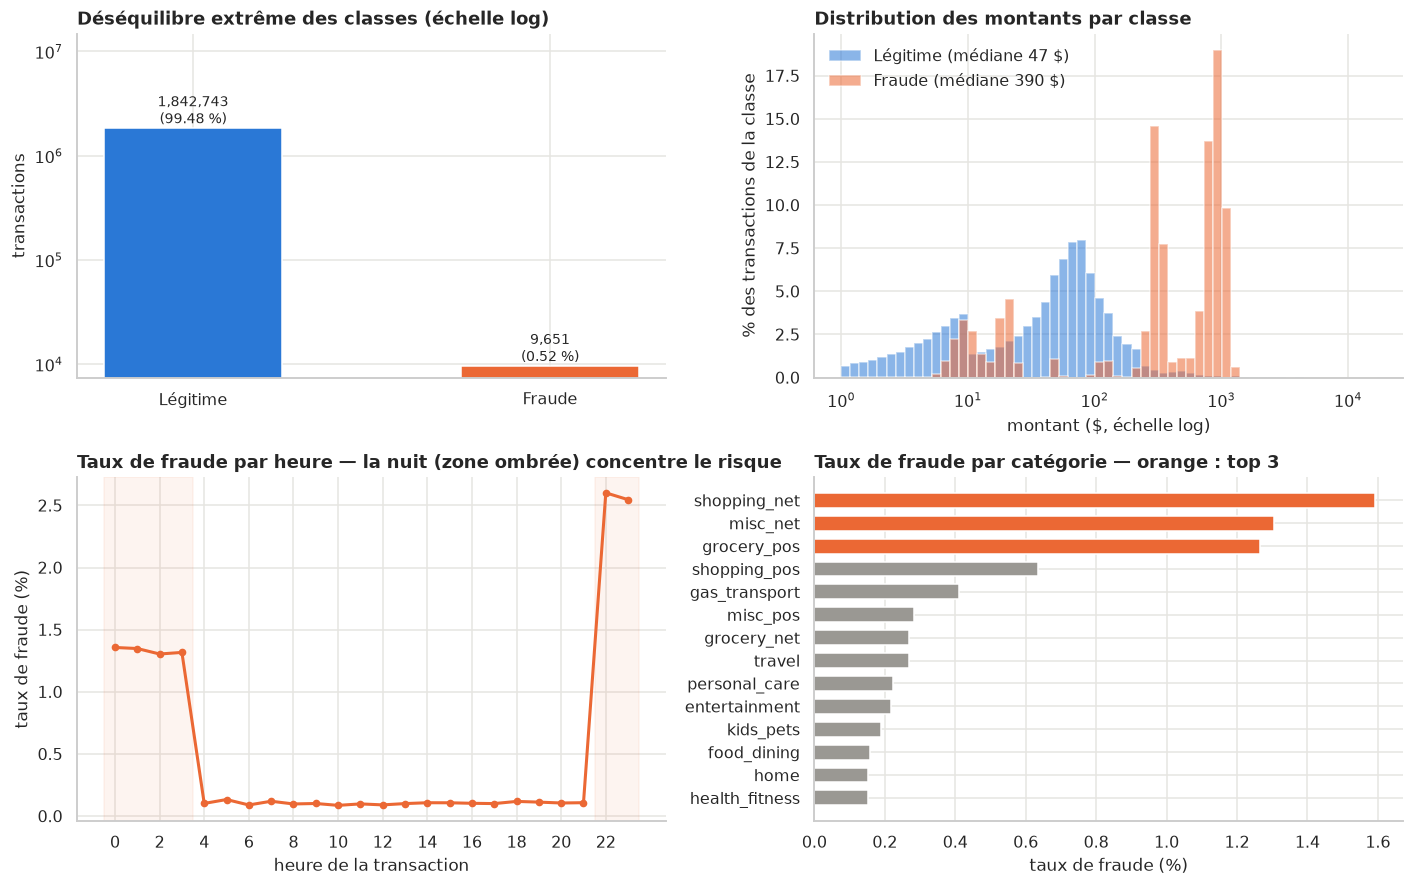

In [9]:
classes = silver.groupBy("is_fraud").count().toPandas().sort_values("is_fraud")
by_hour = silver.groupBy("hour").agg(F.avg("is_fraud").alias("rate"), F.count("*").alias("n")).toPandas().sort_values("hour")
by_cat = silver.groupBy("category").agg(F.avg("is_fraud").alias("rate")).toPandas().sort_values("rate")
amt_sample = (
    silver.sampleBy("is_fraud", {0: 0.03, 1: 1.0}, seed=42).select("amt", "is_fraud").toPandas()
    .assign(classe=lambda d: np.where(d["is_fraud"] == 1, "Fraude", "Légitime"))
)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))

ax = axes[0, 0]
labels = ["Légitime", "Fraude"]
ax.bar(labels, classes["count"], color=[LEGIT, FRAUD], width=0.5)
for i, v in enumerate(classes["count"]):
    ax.text(i, v, f"{v:,}\n({100 * v / classes['count'].sum():.2f} %)", ha="center", va="bottom", fontsize=9)
ax.set_yscale("log")
ax.set_ylim(top=classes["count"].max() * 8)
ax.set_title("Déséquilibre extrême des classes (échelle log)")
ax.set_ylabel("transactions")

ax = axes[0, 1]
bins = np.logspace(0, np.log10(amt_sample["amt"].max()), 60)
for cls in labels:
    sub = amt_sample.loc[amt_sample["classe"] == cls, "amt"]
    ax.hist(sub, bins=bins, weights=np.full(len(sub), 100 / len(sub)), alpha=0.55, color=CLASS_COLORS[cls],
            label=f"{cls} (médiane {sub.median():.0f} $)")
ax.set_xscale("log")
ax.set_ylabel("% des transactions de la classe")
ax.set_title("Distribution des montants par classe")
ax.set_xlabel("montant ($, échelle log)")
ax.legend()

ax = axes[1, 0]
ax.plot(by_hour["hour"], 100 * by_hour["rate"], color=FRAUD, lw=2, marker="o", ms=4)
ax.axvspan(-0.5, 3.5, color=FRAUD, alpha=0.07)
ax.axvspan(21.5, 23.5, color=FRAUD, alpha=0.07)
ax.set_xticks(range(0, 24, 2))
ax.set_title("Taux de fraude par heure — la nuit (zone ombrée) concentre le risque")
ax.set_xlabel("heure de la transaction")
ax.set_ylabel("taux de fraude (%)")

ax = axes[1, 1]
top3 = set(by_cat.nlargest(3, "rate")["category"])
ax.barh(by_cat["category"], 100 * by_cat["rate"],
        color=[FRAUD if c in top3 else NEUTRAL for c in by_cat["category"]], height=0.65)
ax.set_title("Taux de fraude par catégorie — orange : top 3")
ax.set_xlabel("taux de fraude (%)")

plt.tight_layout()
plt.show()

> **Premiers enseignements.** (1) La fraude est **rare** (≈ 1 transaction sur 190) : un modèle qui prédit « jamais de fraude »
> aurait 99,5 % d'*accuracy* et une utilité nulle. (2) Les montants frauduleux sont **~8× plus élevés** en médiane (≈ 390 $ vs ≈ 48 $)
> avec une distribution bimodale (petits tests de carte + gros achats). (3) Le risque explose **entre 22 h et 4 h**. (4) Trois catégories
> concentrent la fraude : **`shopping_net`, `misc_net`, `grocery_pos`**. Ces constats seront testés statistiquement au Jour 4.

---
## 6. Garanties transactionnelles ACID de Delta Lake

### Exercice 6.1 — Journal `_delta_log` & *Schema Enforcement*

In [10]:
# 1. Lecture directe du journal transactionnel JSON (commit n°0) sur HDFS
log_df = spark.read.json(f"{SILVER_MAIN_PATH}/_delta_log/00000000000000000000.json")
print("Actions présentes dans le commit 0 :", [c for c in log_df.columns])
log_df.select("commitInfo.operation", "commitInfo.operationParameters.partitionBy", "commitInfo.operationMetrics.numFiles",
              "commitInfo.operationMetrics.numOutputRows").dropna(how="all").show(truncate=False)
print(f"Fichiers Parquet ajoutés (actions `add`) : {log_df.filter(F.col('add').isNotNull()).count()}")

# 2. Schema Enforcement : un lot au schéma incompatible est rejeté atomiquement
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)
    print("❌ Écriture acceptée : le schéma n'a pas été protégé !")
except Exception as e:
    print("✅ Schema Enforcement validé — écriture invalide bloquée :")
    print("   ", str(e).splitlines()[0][:220])

Actions présentes dans le commit 0 : ['add', 'commitInfo', 'metaData', 'protocol']
+---------+---------------+--------+-------------+
|operation|partitionBy    |numFiles|numOutputRows|
+---------+---------------+--------+-------------+
|WRITE    |["trans_month"]|216     |1852394      |
+---------+---------------+--------+-------------+

Fichiers Parquet ajoutés (actions `add`) : 216


✅ Schema Enforcement validé — écriture invalide bloquée :
    [DELTA_METADATA_MISMATCH] A metadata mismatch was detected when writing to the Delta table.


### Exercice 6.2 — Scénario métier : lot de *chargebacks*, `MERGE INTO`, *Time Travel* et `RESTORE`

En banque, l'étiquette de fraude arrive souvent **plusieurs semaines après** la transaction : le porteur conteste un débit
(*chargeback*) et l'enquête confirme la fraude. Nous simulons :
1. la réception d'un **lot de 25 chargebacks** sur des transactions de décembre 2020 (→ `is_fraud = 1`, `label_source = 'chargeback'`)
   et d'**une transaction arrivée en retard** (*late arriving data*) → **upsert** atomique `MERGE INTO` ;
2. l'**audit** du changement par *Time Travel* (`versionAsOf`) ;
3. la découverte que ce lot était un **doublon de test du fournisseur** → **retour arrière** instantané avec `RESTORE`,
   sans recopier un seul fichier de données.

> La condition de jointure inclut `trans_month` : Delta **élague les partitions** et ne réécrit que les fichiers de décembre 2020.

In [11]:
target_delta = DeltaTable.forPath(spark, SILVER_MAIN_PATH)
v_before = target_delta.history(1).select("version").first()[0]
fraud_before = silver.filter("is_fraud = 1").count()

dec = silver.filter("trans_month = '2020-12'")
chargebacks = (
    dec.filter("is_fraud = 0").orderBy("trans_num").limit(25)
    .withColumn("is_fraud", F.lit(1)).withColumn("label_source", F.lit("chargeback"))
)
late_arrival = (
    dec.orderBy(F.desc("trans_ts")).limit(1)
    .withColumn("trans_num", F.concat(F.lit("late_"), F.col("trans_num")))
    .withColumn("label_source", F.lit("late_arrival"))
)
updates = chargebacks.unionByName(late_arrival)

(
    target_delta.alias("t")
    .merge(updates.alias("s"), "t.trans_num = s.trans_num AND t.trans_month = s.trans_month")
    .whenMatchedUpdate(set={"is_fraud": "s.is_fraud", "label_source": "s.label_source"})
    .whenNotMatchedInsertAll()
    .execute()
)

history_df = spark.sql(f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`")
history_df.select("version", "timestamp", "operation", "operationMetrics").show(5, truncate=95)

v_after = target_delta.history(1).select("version").first()[0]
fraud_v_before = spark.read.format("delta").option("versionAsOf", v_before).load(SILVER_MAIN_PATH).filter("is_fraud = 1").count()
fraud_v_after = spark.read.format("delta").load(SILVER_MAIN_PATH).filter("is_fraud = 1").count()
print(f"⏪ Time Travel — fraudes en version {v_before} : {fraud_v_before:,} | version {v_after} : {fraud_v_after:,} "
      f"(+{fraud_v_after - fraud_v_before})")
spark.read.format("delta").load(SILVER_MAIN_PATH).groupBy("label_source").count().show()

+-------+-----------------------+---------+-----------------------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                               operationMetrics|
+-------+-----------------------+---------+-----------------------------------------------------------------------------------------------+
|      1|2026-11-21 07:53:21.483|    MERGE|{numTargetRowsCopied -> 105830, numTargetRowsDeleted -> 0, numTargetBytesRemoved -> 9333432,...|
|      0|2026-11-21 07:52:57.322|    WRITE|{numFiles -> 216, numRemovedFiles -> 0, numRemovedBytes -> 0, numOutputRows -> 1852394, numO...|
+-------+-----------------------+---------+-----------------------------------------------------------------------------------------------+



⏪ Time Travel — fraudes en version 0 : 9,651 | version 1 : 9,676 (+25)


+------------+-------+
|label_source|  count|
+------------+-------+
|  chargeback|     25|
|     initial|1852369|
|late_arrival|      1|
+------------+-------+



In [12]:
# Le lot s'avère erroné -> retour arrière atomique (simple nouveau commit qui pointe vers les anciens fichiers)
target_delta.restoreToVersion(v_before)

restored = spark.read.format("delta").load(SILVER_MAIN_PATH)
fraud_restored = restored.filter("is_fraud = 1").count()
assert fraud_restored == fraud_before and restored.count() == silver_count, "RESTORE incomplet !"
print(f"✅ RESTORE vers la version {v_before} : {restored.count():,} lignes, {fraud_restored:,} fraudes (état initial retrouvé)")

history_df = spark.sql(f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`")
history_df.select("version", "timestamp", "operation", "operationMetrics").show(5, truncate=95)
assert history_df.count() >= 2, "Au moins une opération MERGE/UPDATE est attendue (version >= 1) !"

✅ RESTORE vers la version 0 : 1,852,394 lignes, 9,651 fraudes (état initial retrouvé)
+-------+-----------------------+---------+-----------------------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                               operationMetrics|
+-------+-----------------------+---------+-----------------------------------------------------------------------------------------------+
|      2|2026-11-21 07:53:35.165|  RESTORE|{numRestoredFiles -> 7, removedFilesSize -> 8603210, numRemovedFiles -> 1, restoredFilesSize...|
|      1|2026-11-21 07:53:21.483|    MERGE|{numTargetRowsCopied -> 105830, numTargetRowsDeleted -> 0, numTargetBytesRemoved -> 9333432,...|
|      0|2026-11-21 07:52:57.322|    WRITE|{numFiles -> 216, numRemovedFiles -> 0, numRemovedBytes -> 0, numOutputRows -> 1852394, numO...|
+-------+-----------------------+---------+-------------------------------

---
## 🧾 Bilan du Jour 2

- ✅ **Qualité auditée** : 0 manquant, 0 doublon, 0 violation de domaine ; **2 anomalies** corrigées (`unix_time` décalé de 7 ans, préfixe `fraud_`).
- ✅ **RGPD** : identifiants directs supprimés, carte pseudonymisée (SHA-256 salé), date de naissance remplacée par l'âge.
- ✅ **20 features** anti-fraude dont 5 de **vélocité** calculées sans fuite d'information (fenêtres sur le passé uniquement).
- ✅ **Jointure inter-datasets** `BroadcastHashJoin` sur dimension à clé unique : explosion N-à-M évitée et **prouvée par le calcul**.
- ✅ **ACID** : *Schema Enforcement*, `MERGE` avec élagage de partitions, audit par *Time Travel*, `RESTORE` atomique.

➡️ **Jour 3** : indicateurs robustes, Pareto des pertes, dynamique temporelle et construction des tables Gold du dashboard.